# 03 — Community detection on the reply network


* In this notebook we are taking the response graph from the last Notebook and try to answer the question : "How the conversations cluster?"
* First, we run four different community detection algorithms (Louvain, CNM, label propagation, FluidC) on the same graph and compare them based on modularity.
* Next, we compare the identified communities with the three data streams (equities, macro, crypto) and answer the question "do the search streams align with the network's natural groups?" using a table and the assortativity coefficient.


## 1. Load the graphs from notebook 02


In [1]:
import pickle, itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import community as nxc
from sklearn.metrics import normalized_mutual_info_score as nmi

PROC, FIG, SEED = "../data/processed", "../figures", 42
with open(f"{PROC}/graphs.pkl", "rb") as f:
    d = pickle.load(f)
graphs, giants = d["graphs"], d["giants"]
nodes = pd.read_csv(f"{PROC}/nodes_all.csv", index_col="did")
handle_of = nodes.handle.to_dict()

# community detection works on the undirected, weighted giant component (a reply in either direction is a tie)
giant = giants["all"]
print("giant component:", giant.number_of_nodes(), "nodes,", giant.number_of_edges(), "edges")

giant component: 11140 nodes, 13667 edges


## 2. Three algorithm families


Running community detection algorithms based on different logics on the same graph and comparing which one yields better partitioning using modularity.

In [2]:
def as_labels(partition, G):
    # list of sets -> {node: community id}, ids ordered by community size
    parts = sorted(partition, key=len, reverse=True)
    return {n: i for i, p in enumerate(parts) for n in p}

results = {}
louvain = nxc.louvain_communities(giant, weight="weight", seed=SEED)          # modularity optimisation (multi-level)
results["Louvain"] = louvain
cnm = nxc.greedy_modularity_communities(giant, weight="weight")               # Clauset–Newman–Moore, agglomerative
results["Greedy modularity (CNM)"] = cnm
lpa = list(nxc.asyn_lpa_communities(giant, weight="weight", seed=SEED))       # label propagation, no objective function
results["Label propagation"] = lpa
for k in (3, 10):                                                             # FluidC needs a connected graph and a chosen k
    results[f"FluidC k={k}"] = list(nxc.asyn_fluidc(giant, k=k, seed=SEED))

rows = []
for name, part in results.items():
    sizes = sorted((len(p) for p in part), reverse=True)
    rows.append({"algorithm": name, "communities": len(part), "modularity Q": nxc.modularity(giant, part, weight="weight"),
                 "largest": sizes[0], "share in top 10": sum(sizes[:10]) / giant.number_of_nodes(),
                 "communities with ≥ 50 nodes": sum(s >= 50 for s in sizes)})
comm_table = pd.DataFrame(rows).set_index("algorithm")
comm_table.round(4)

,communities,modularity Q,largest,share in top 10,communities with ≥ 50 nodes
algorithm,,,,,
Louvain,67,0.8599,688,0.3739,59
Greedy modularity (CNM),86,0.8582,951,0.4639,46
Label propagation,1682,0.7242,628,0.2146,32
FluidC k=3,3,0.5449,5245,1.0000,3
FluidC k=10,10,0.7480,2257,1.0000,10


Louvain gives the highest modularity, with 67 communities and Q = 0.860.

## 3. Stability across seeds and agreement between algorithms


Since we know that Louvain depends on the initial state; to demonstrate that the result is not due to chance, one can run it again with different seeds and measure the similarity between the resulting partitions.

In [3]:
base = as_labels(louvain, giant)
order = list(giant.nodes())
runs = [base] + [as_labels(nxc.louvain_communities(giant, weight="weight", seed=s), giant) for s in (1, 2, 3, 4)]
pairs = [nmi([a[n] for n in order], [b[n] for n in order]) for a, b in itertools.combinations(runs, 2)]
print(f"Louvain, 5 seeds: NMI between runs = {np.mean(pairs):.3f} (min {np.min(pairs):.3f}), "
      f"communities per run = {[len(set(r.values())) for r in runs]}")
lab_cnm, lab_lpa = as_labels(cnm, giant), as_labels(lpa, giant)
print(f"Louvain vs CNM: NMI = {nmi([base[n] for n in order], [lab_cnm[n] for n in order]):.3f}")
print(f"Louvain vs LPA: NMI = {nmi([base[n] for n in order], [lab_lpa[n] for n in order]):.3f}")

Louvain, 5 seeds: NMI between runs = 0.904 (min 0.888), communities per run = [67, 69, 70, 65, 70]
Louvain vs CNM: NMI = 0.815
Louvain vs LPA: NMI = 0.726


Across five seeds, the average NMI is 0.904, with a minimum of 0.888; the number of communities ranges from 65 to 70 (67, 69, 70, 65, 70). In other words, the partitioning remains largely consistent despite randomness. The agreement between Louvain and CNM is 0.815, and between Louvain and LPA, it is 0.726; algorithms operating on different logics identify largely the same groups. The communities genuinely exist in the data; they are not an artifact produced by the algorithm.

## 4. Communities vs the query streams (observable vs detected groups)


To see the extent to which the communities identified by the algorithm overlap with the three streams from which the data was collected (equities, macro, and crypto).

In [4]:
nodes["community"] = pd.Series(base)                      # Louvain id (0 = largest), NaN outside the giant component
in_giant = nodes.community.notna()
nodes["community"] = nodes.community.astype("Int64")

top_comms = nodes.loc[in_giant].community.value_counts().head(12).index
ct = pd.crosstab(nodes.loc[in_giant & nodes.community.isin(top_comms), "community"],
                 nodes.loc[in_giant & nodes.community.isin(top_comms), "dominant_stream"])
ct["size"] = ct.sum(axis=1)
ct["purity"] = ct[["equities", "macro", "crypto"]].max(axis=1) / ct[["equities", "macro", "crypto"]].sum(axis=1)
ct.sort_values("size", ascending=False)

dominant_stream,crypto,equities,macro,reply-only,size,purity
community,,,,,,
0,29,105,45,509,688,0.586592
1,24,131,178,306,639,0.534535
2,23,60,142,204,429,0.631111
3,96,30,25,270,421,0.635762
4,8,70,54,288,420,0.530303
5,15,53,93,239,400,0.577640
6,5,27,22,257,311,0.500000
7,22,107,46,120,295,0.611429
8,6,6,145,129,286,0.923567


In 11 of the 12 communities, the single largest group is "reply-only" (509 out of 688 in Community 0); the only exception is Community 8, where "macro" (145) surpasses "reply-only" (129). The majority of those sustaining the conversation are ordinary responders who do not use our keywords.

In [5]:
# does the network mix across streams? attribute assortativity on the dominant stream (nodes with at least one collected post)
sub = giant.subgraph([n for n in giant.nodes() if nodes.loc[n, "dominant_stream"] != "reply-only"])
nx.set_node_attributes(sub, nodes.loc[list(sub.nodes()), "dominant_stream"].to_dict(), "stream")
print("nodes with a known stream:", sub.number_of_nodes(), "| edges among them:", sub.number_of_edges())
print("attribute assortativity by stream:", round(nx.attribute_assortativity_coefficient(sub, "stream"), 3))
# crossing edges (between Louvain communities)
cross = sum(1 for u, v in giant.edges() if base[u] != base[v])
print(f"edges between communities: {cross} of {giant.number_of_edges()} ({cross/giant.number_of_edges():.1%})")

nodes with a known stream: 4194 | edges among them: 4265
attribute assortativity by stream: 0.305
edges between communities: 1704 of 13667 (12.5%)


There are 4,265 edges among the 4,194 nodes with known flow; the flow assortativity is 0.305. This is positive but moderate: people tend to converse more with others in their own subject area, yet the flows do not constitute closed chambers. Only 1,704 (12.5%) of the 13,667 edges are inter-community; 87.5% of the edges remain within the community, which is the concrete manifestation of Q=0.86.

## 5. Who is each community built around?


To assign names to the communities, we are listing the accounts that received the most responses in each one.

In [6]:
indeg = dict(graphs["all"].in_degree())
rows = []
for c in top_comms:
    members = nodes.index[nodes.community == c]
    top = sorted(members, key=lambda n: indeg.get(n, 0), reverse=True)[:4]
    rows.append({"community": c, "size": len(members),
                 "most replied-to accounts": ", ".join(f"{handle_of[n]} ({indeg.get(n,0)})" for n in top)})
pd.DataFrame(rows).set_index("community")

,size,most replied-to accounts
community,,
0,688,"atrupar.com (738), aubrey333.bsky.social (8), ..."
1,639,"carlquintanilla.bsky.social (280), steveliesma..."
2,429,"peark.es (66), claudia-sahm.bsky.social (55), ..."
3,421,"disabilitystor1.bsky.social (233), joshtpm.bsk..."
4,420,"meidastouch.com (391), deanobeidallah.bsky.soc..."
5,400,"crampell.bsky.social (122), justinwolfers.bsky..."
6,311,"muellershewrote.com (373), brat2381.bsky.socia..."
7,295,"sundaedivine.lol (83), ronfilipkowski.bsky.soc..."
8,286,"andrewskeets.bsky.social (32), cgd-2.bsky.soci..."


## 6. Community structure per stream


Rerunning Louvain on each flow's own response graph to see whether the clustering varies according to the flow.

In [7]:
rows = []
for s in ["equities", "macro", "crypto"]:
    g = giants[s]
    part = nxc.louvain_communities(g, weight="weight", seed=SEED)
    sizes = sorted((len(p) for p in part), reverse=True)
    rows.append({"stream": s, "giant nodes": g.number_of_nodes(), "communities": len(part),
                 "modularity Q": nxc.modularity(g, part, weight="weight"), "largest community": sizes[0],
                 "communities ≥ 50": sum(x >= 50 for x in sizes)})
pd.DataFrame(rows).set_index("stream").round(3)

,giant nodes,communities,modularity Q,largest community,communities ≥ 50
stream,,,,,
equities,3665,54,0.896,435,27
macro,4043,51,0.849,325,26
crypto,2560,51,0.906,263,16


## 7. Network figure


Reducing an 11,000-node network to a readable image; representing communities with color and hub accounts with labels.

2-core, 12 largest communities: 1114 nodes, 2071 edges


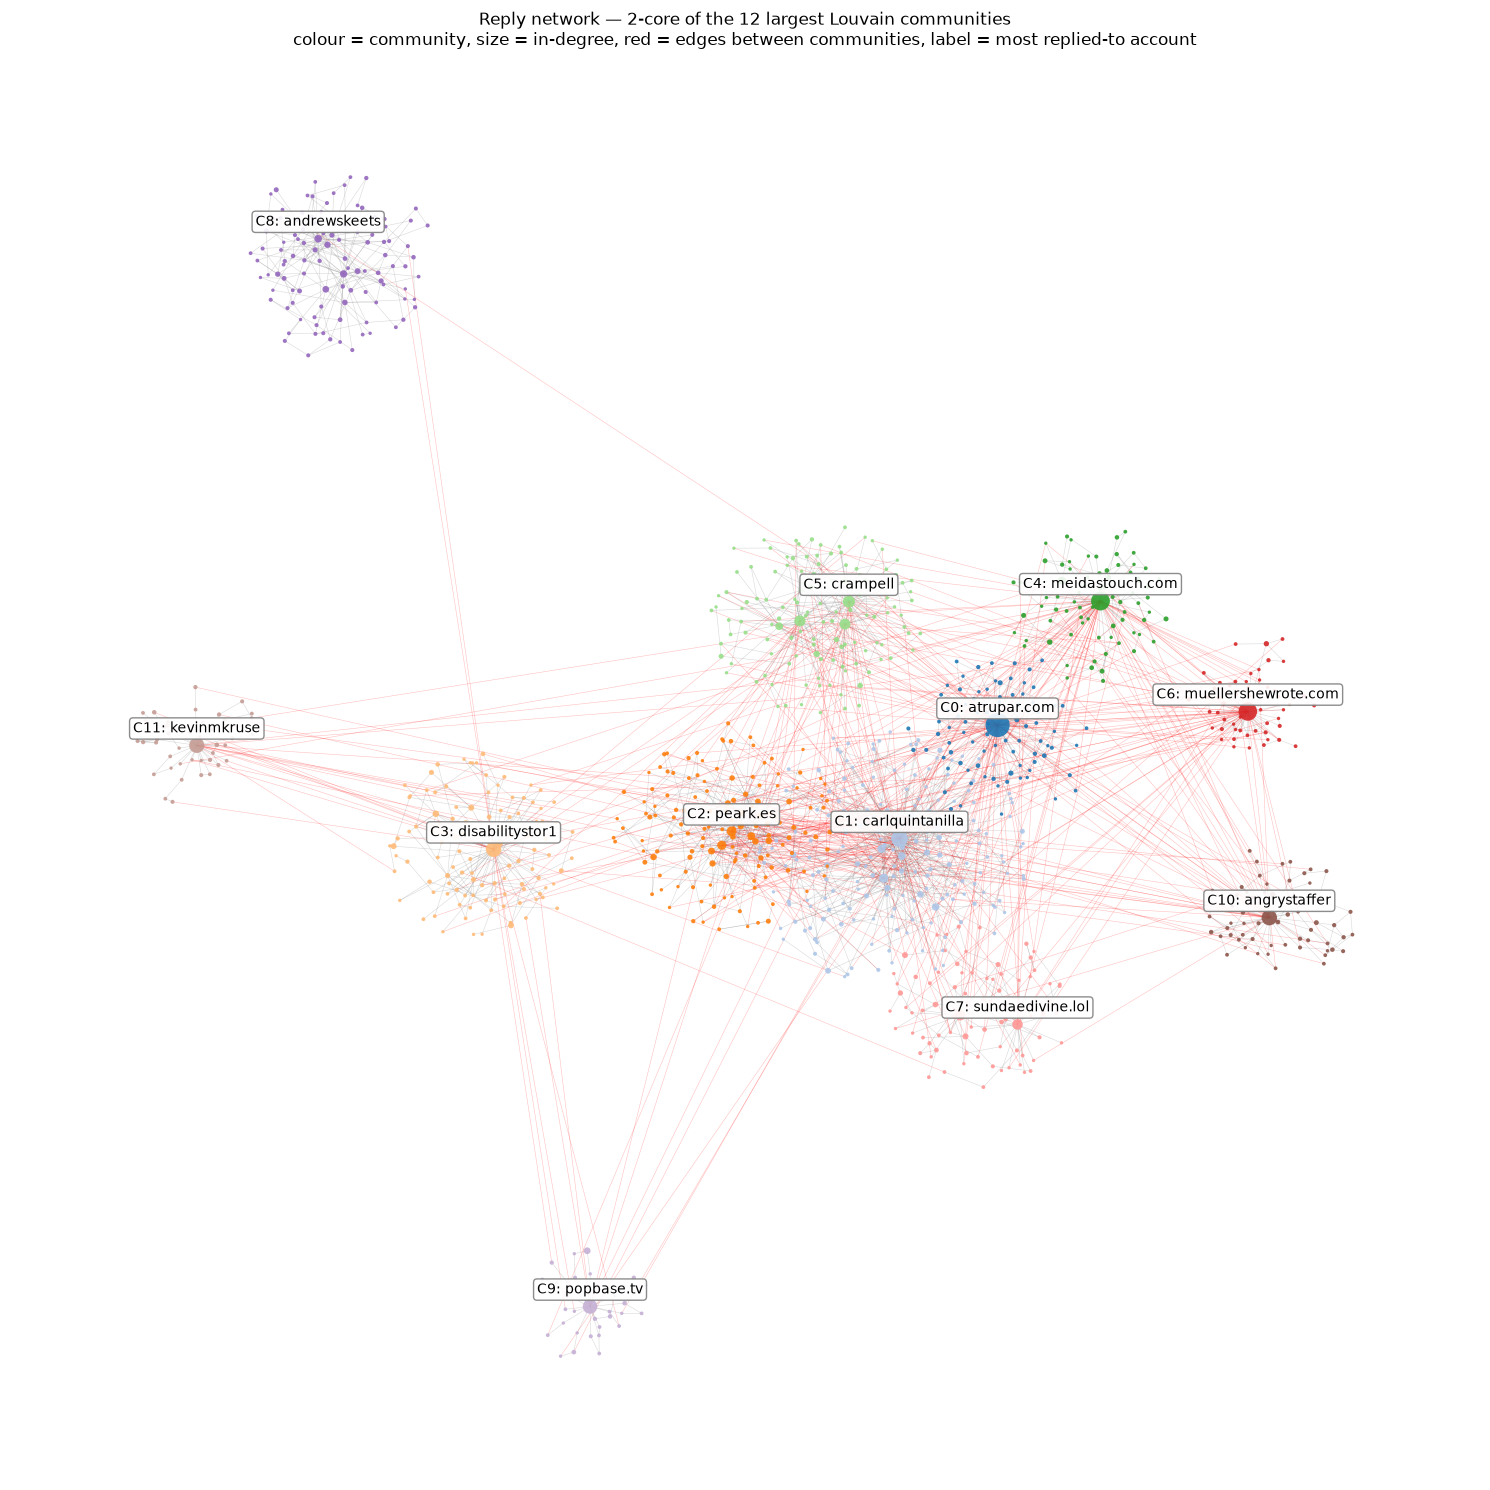

In [8]:
# drawing 11k nodes gives a hairball, so I draw the 2-core restricted to the 12 largest Louvain communities
core = nx.k_core(giant, k=2)
keep = [n for n in core.nodes() if base[n] in set(top_comms)]
core = core.subgraph(keep).copy()
print("2-core, 12 largest communities:", core.number_of_nodes(), "nodes,", core.number_of_edges(), "edges")

# community-aware layout: communities are placed first as super-nodes, then members around their own centre
comm_of = {n: base[n] for n in core.nodes()}
C = nx.Graph(); C.add_nodes_from(set(comm_of.values()))
for u, v in core.edges():
    cu, cv = comm_of[u], comm_of[v]
    if cu != cv:
        C.add_edge(cu, cv, weight=(C[cu][cv]["weight"] + 1) if C.has_edge(cu, cv) else 1)
pos_C = nx.spring_layout(C, seed=SEED, weight="weight", k=2.5, scale=5)
sizes = pd.Series(comm_of).value_counts()
pos = {}
for c in C.nodes():
    members = [n for n in core.nodes() if comm_of[n] == c]
    sub = core.subgraph(members)
    local = nx.spring_layout(sub, seed=SEED, k=0.5) if len(members) > 1 else {members[0]: np.zeros(2)}
    r = 1.1 * np.sqrt(sizes[c] / sizes.max())     # radius grows with the square root of the community size
    for n, xy in local.items():
        pos[n] = pos_C[c] + r * xy

palette = plt.cm.tab20.colors
color_of = {c: palette[i % 20] for i, c in enumerate(top_comms)}
node_color = [color_of[base[n]] for n in core.nodes()]
node_size = [6 + 1.5 * indeg.get(n, 0) ** 0.8 for n in core.nodes()]
crossing = [(u, v) for u, v in core.edges() if base[u] != base[v]]
inside = [(u, v) for u, v in core.edges() if base[u] == base[v]]

fig, ax = plt.subplots(figsize=(15, 15))
nx.draw_networkx_edges(core, pos, edgelist=inside, alpha=0.3, width=0.4, edge_color="grey", ax=ax)
nx.draw_networkx_edges(core, pos, edgelist=crossing, alpha=0.25, width=0.4, edge_color="red", ax=ax)
nx.draw_networkx_nodes(core, pos, node_color=node_color, node_size=node_size, linewidths=0, alpha=0.9, ax=ax)
# label the most replied-to account of each community
for c in C.nodes():
    hub = max((n for n in core.nodes() if comm_of[n] == c), key=lambda n: indeg.get(n, 0))
    ax.annotate(f"C{c}: {handle_of[hub].replace('.bsky.social', '')}", pos[hub], fontsize=10, ha="center", va="bottom",
                xytext=(0, 7), textcoords="offset points", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="grey", alpha=0.9))
ax.set_title("Reply network — 2-core of the 12 largest Louvain communities\n"
             "colour = community, size = in-degree, red = edges between communities, label = most replied-to account", fontsize=12)
ax.axis("off"); plt.tight_layout(); plt.savefig(f"{FIG}/03_network_communities.png", dpi=150); plt.show()

Each community forms a cluster in its own color, with a large hub node at its center; red edges serve as the few bridges connecting the communities. The ratio of gray to red visually illustrates the 87.5% internal / 12.5% ​​external split observed in Cell 5.

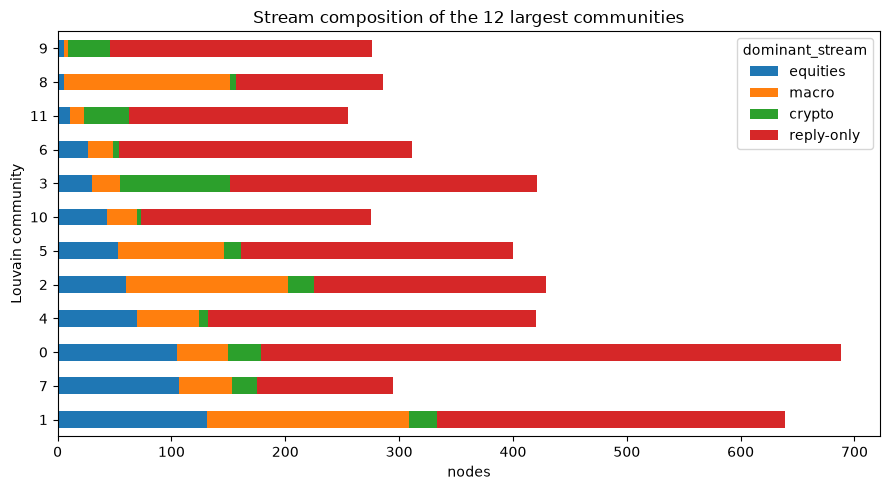

In [9]:
# composition of the largest communities by stream
comp = ct[["equities", "macro", "crypto", "reply-only"]].sort_values("equities", ascending=False)
ax = comp.plot(kind="barh", stacked=True, figsize=(9, 5))
ax.set_xlabel("nodes"); ax.set_ylabel("Louvain community"); ax.set_title("Stream composition of the 12 largest communities")
plt.tight_layout(); plt.savefig(f"{FIG}/03_community_composition.png", dpi=150); plt.show()

nodes.to_csv(f"{PROC}/nodes_all.csv")
comm_table.round(4).to_csv(f"{PROC}/community_algorithms.csv")
with open(f"{PROC}/communities.pkl", "wb") as f:
    pickle.dump({"louvain": base, "cnm": lab_cnm, "lpa": lab_lpa}, f)